In [ ]:
import gc, json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from tqdm.auto import tqdm

import traceback

sys.path.insert(0, "kev")
from models.kev_pointer import KevPointerModel
from cycler import cycler

LANCET_PALETTE = ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"]
plt.rcParams["axes.prop_cycle"] = cycler(color=LANCET_PALETTE)


def make_record(row):
    attr_code = row["attribute"]
    group_val = row["group"]
    personas = {attr_code: group_val}
    return {
        "qid": row["qid"],
        "type": row["type"],
        "question": row["question"],
        "option_texts": row["option_texts"],
        "country": row["c_alphan"],
        "personas": personas,
        "attribute": attr_code,
        "persona": f"{PERSONA_NAMES[attr_code]}={group_val}",
        "human_dist": row["human_dist"],
    }


def consensus(probs):
    num_options = len(probs)
    if num_options <= 1:
        raise ValueError(f"consensus requires at least 2 options, got {num_options}")
    scale_points = np.arange(1, num_options + 1, dtype=float)
    mean_score = float(np.dot(scale_points, probs))
    return float(
        1.0 + np.sum(probs * np.log2(1.0 - np.abs(scale_points - mean_score) / (num_options - 1) + 1e-12))
    )
def dist_kl_w1(human_dist, model_dist):
    clipped = np.clip(model_dist, 1e-12, 1.0)
    mask = human_dist > 0
    kl = float(np.sum(human_dist[mask] * np.log2(human_dist[mask] / clipped[mask])))
    w1 = float(np.abs(np.cumsum(human_dist)[:-1] - np.cumsum(model_dist)[:-1]).sum() / (len(human_dist) - 1))
    return kl, w1

def build_persona_dataset(df, attr_sets=None):
    if attr_sets is None:
        sub = df
    else:
        sets = [[attr_sets]] if isinstance(attr_sets, str) else attr_sets
        allowed = {cols[0] if isinstance(cols, (list, tuple)) else cols for cols in sets}
        sub = df[df["attribute"].isin(allowed)]
    return [make_record(row) for row in sub.to_dict("records")]


def make_view(rec):
    qid = rec["qid"]
    q_type = rec["type"]
    option_texts = rec["option_texts"]
    human_dist = rec["human_dist"]

    state_lines = [f"{PERSONA_NAMES['c_alphan']}: {rec['country']}"]
    state_lines.extend(f"{PERSONA_NAMES[c]}: {v}" for c, v in rec["personas"].items())

    if q_type == "score":
        criteria = option_texts
        target = {str(i): float(p) for i, p in enumerate(human_dist)}
    elif q_type == "choice":
        criteria = {text: None for text in option_texts}
        target = {text: float(p) for text, p in zip(option_texts, human_dist)}
    else:
        raise ValueError(f"{qid}: unexpected question type {q_type!r}")

    return {
        "state": "\n".join(state_lines),
        "questions": {
            qid: {
                "type": q_type,
                "instructions": rec["question"],
                "criteria": criteria,
                "target": target,
            }
        },
    }
def free_gpu():
    if hasattr(sys, "last_traceback") and sys.last_traceback is not None:
        traceback.clear_frames(sys.last_traceback)
        sys.last_traceback = None
    if hasattr(sys, "last_value"):
        sys.last_value = None
    if hasattr(sys, "last_type"):
        sys.last_type = None
    if hasattr(sys, "last_exc"):
        sys.last_exc = None
    gc.collect()
    torch.cuda.empty_cache()


@torch.no_grad()
def predict_probs(model, records, batch_size=64, show_progress=True, autocast_bf16=False):
    was_training = model.training
    model.eval()
    preds = []
    iterator = range(0, len(records), batch_size)
    if show_progress:
        iterator = tqdm(iterator, desc="predict", unit="batch", leave=False)
    for start in iterator:
        batch = records[start:start + batch_size]
        prepared = [model.prepare(make_view(r)) for r in batch]
        if autocast_bf16:
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits_batch = model.forward([enc for enc, _ in prepared])
        else:
            logits_batch = model.forward([enc for enc, _ in prepared])
        for question_logits in logits_batch:
            if len(question_logits) != 1:
                raise ValueError(f"Expected 1 question per record, got {len(question_logits)}")
            preds.append(torch.softmax(question_logits[0].float(), dim=-1).cpu().numpy())
    if was_training:
        model.train()
    return preds


In [35]:
PERSONA_NAMES = {
    "c_alphan": "Country",
    "CREGION": "Region",
    "EDUCATION": "Education",
    "INCOME": "Income",
    "POLIDEOLOGY": "Political ideology",
    "POLPARTY": "Political party",
    "RACE": "Race",
    "RELIG": "Religion",
    "SEX": "Sex",
}
NAMES_PERSONA = {v: k for k,v in PERSONA_NAMES.items()}

subpop_path = Path("data/subpop/subpop_eval.jsonl")
raw_rows = []
with subpop_path.open() as f:
    for line in f:
        block = json.loads(line)
        prefix, attr_code, group_val = block["group"].split("/", 2)
        if prefix != "SUBPOP":
            raise ValueError(f"Unexpected group prefix in {block['group']!r}")
        persona_label = PERSONA_NAMES[attr_code]
        if block["persona"][persona_label] != group_val:
            raise ValueError(f"{block['group']}: persona mismatch {block['persona']}")
        country = block["persona"]["Country"]

        for qid, q in block["questions"].items():
            q_type = q["type"]
            if q_type == "score":
                option_texts = list(q["criteria"])
                human_dist = np.array([q["target"][str(i)] for i in range(len(option_texts))], dtype=np.float64)
            elif q_type == "choice":
                option_texts = list(q["criteria"].keys())
                human_dist = np.array([q["target"][opt] for opt in option_texts], dtype=np.float64)
            else:
                raise ValueError(f"{qid}: unexpected question type {q_type!r}")

            raw_rows.append({
                "qid": qid,
                "type": q_type,
                "question": q["instructions"],
                "option_texts": option_texts,
                "c_alphan": country,
                "attribute": attr_code,
                "group": group_val,
                "human_dist": human_dist,
            })

subpop_df = pd.DataFrame(raw_rows)
print(f"subpop_eval: {len(subpop_df):>7,} records across {subpop_df['qid'].nunique():>3} questions and {subpop_df['group'].nunique():>2} subpopulations")

subpop_df.head(2)

subpop_eval:   2,926 records across 133 questions and 22 subpopulations


,qid,type,question,option_texts,c_alphan,attribute,group,human_dist
0,natspac,score,We are faced with many problems in this countr...,"[Too little, About right, Too much]",United States,CREGION,Northeast,"[0.3076, 0.4115, 0.2809]"
1,natenvir,score,We are faced with many problems in this countr...,"[Too little, About right, Too much]",United States,CREGION,Northeast,"[0.699, 0.1868, 0.1142]"


In [36]:
single_persona_attrs = [c for c in PERSONA_NAMES.keys() if c != "c_alphan"]
subpop_records = build_persona_dataset(subpop_df, attr_sets=single_persona_attrs)
print(f"SubPOP eval records: {len(subpop_records):,}")
pd.DataFrame(subpop_records)[["qid", "type", "attribute", "persona", "human_dist"]].head(5)


SubPOP eval records: 2,926


,qid,type,attribute,persona,human_dist
0,natspac,score,CREGION,Region=Northeast,"[0.3076, 0.4115, 0.2809]"
1,natenvir,score,CREGION,Region=Northeast,"[0.699, 0.1868, 0.1142]"
2,natheal,score,CREGION,Region=Northeast,"[0.7429, 0.2225, 0.0346]"
3,natcity,score,CREGION,Region=Northeast,"[0.5976, 0.2711, 0.1312]"
4,natdrug,score,CREGION,Region=Northeast,"[0.092, 0.1868, 0.7212]"


['Country',
 'Region',
 'Education',
 'Income',
 'Political ideology',
 'Political party',
 'Race',
 'Religion',
 'Sex']

In [48]:
print(list(NAMES_PERSONA.keys()))

attr = "Political party"
target_attr = NAMES_PERSONA[attr]
attr_label = PERSONA_NAMES[target_attr]
attr_dataset = build_persona_dataset(
    subpop_df, attr_sets=[[target_attr]],
)
attr_levels = list(dict.fromkeys(s["personas"][target_attr] for s in attr_dataset))
print(f"{target_attr} ({attr_label}) levels: {attr_levels}")


['Country', 'Region', 'Education', 'Income', 'Political ideology', 'Political party', 'Race', 'Religion', 'Sex']
POLPARTY (Political party) levels: ['Democrat', 'Republican']


In [49]:
records_by_qid = {}
for s in attr_dataset:
    records_by_qid.setdefault(s["qid"], {})[s["personas"][target_attr]] = s

mixed_rows = []
for qid, grp in records_by_qid.items():
    if set(grp.keys()) != set(attr_levels):
        raise ValueError(f"{qid}: expected {set(attr_levels)}, got {set(grp.keys())}")
    first_rec = grp[attr_levels[0]]
    if first_rec["type"] != "score" or len(first_rec["option_texts"]) != 5:
        continue
    scale_points = np.arange(1, len(first_rec["option_texts"]) + 1, dtype=float)
    row_dict = {"qid": qid, "question": first_rec["question"]}
    means = []
    for lvl in attr_levels:
        dist = grp[lvl]["human_dist"]
        lvl_mean = float(np.dot(scale_points, dist))
        means.append(lvl_mean)
        row_dict[f"mean_{lvl}"] = round(lvl_mean, 3)
        row_dict[f"cns_{lvl}"] = round(consensus(dist), 3)
    row_dict["mean_diff"] = round(max(means) - min(means), 3)
    mixed_rows.append(row_dict)

mixed_df = pd.DataFrame(mixed_rows).sort_values("mean_diff", ascending=False).reset_index(drop=True)
mean_cols = [f"mean_{lvl}" for lvl in attr_levels]
cns_cols = [f"cns_{lvl}" for lvl in attr_levels]
display(mixed_df[["qid", *mean_cols, "mean_diff", *cns_cols, "question"]].head(12))


,qid,mean_Democrat,mean_Republican,mean_diff,cns_Democrat,cns_Republican,question
0,letin1a,2.691,3.936,1.245,0.616,0.600,Do you think the number of immigrants to Ameri...
1,marhomo,1.732,2.884,1.152,0.529,0.417,Do you agree or disagree? Homosexual couples s...
2,news,3.438,4.140,0.702,0.279,0.454,How often do you read the newspaper - every da...
3,fehire,2.050,2.708,0.658,0.654,0.550,"Please tell me whether you strongly agree, agr..."
4,granborn,2.401,1.786,0.616,0.198,0.426,Were all of your four grandparents born in thi...
5,parsol,2.225,2.245,0.020,0.574,0.600,Compared to your parents when they were the ag...
6,finrela,3.043,3.028,0.015,0.700,0.750,"Compared with American families in general, wo..."


In [51]:
# n_lvls = len(attr_levels)
# fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.5), sharey=True)
# bar_width = 0.76 / n_lvls

# for ax, (_, row) in zip(axes.flat, mixed_df[["qid", "question"]].head(4).iterrows()):
#     qid = row["qid"]
#     opts = records_by_qid[qid][attr_levels[0]]["option_texts"]
#     x = np.arange(len(opts))

#     all_bars = []
#     for i, lvl in enumerate(attr_levels):
#         rec = records_by_qid[qid][lvl]
#         vals = rec["human_dist"] * 100.0
#         cns_val = consensus(rec["human_dist"])
#         offset = (i - (n_lvls - 1) / 2.0) * bar_width
#         bars = ax.bar(
#             x + offset,
#             vals,
#             width=bar_width,
#             label=f"{lvl} (Cns={cns_val:.2f})",
#             color=LANCET_PALETTE[i % len(LANCET_PALETTE)],
#             alpha=0.9,
#         )
#         all_bars.extend(bars)

#     ax.axhline(20.0, color="#6E6A64", linestyle="--", linewidth=1.0, alpha=0.7, label="Uniform (20%)")

#     for bar in all_bars:
#         h = bar.get_height()
#         ax.text(bar.get_x() + bar.get_width() / 2, h + 0.8, f"{h:.0f}%", ha="center", va="bottom", fontsize=7.5)

#     short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral") for o in opts]
#     short_opts = [o[:10] for o in short_opts]
#     ax.set_xticks(x)
#     ax.set_xticklabels(short_opts, rotation=18, ha="right", fontsize=9)
#     ax.set_title(f"{qid}: {row['question'][-30:]}", fontsize=8, fontweight="bold")
#     ax.grid(axis="y", linestyle=":", alpha=0.5)
#     ax.legend(frameon=True, fontsize=8, loc="upper right")

# axes[0, 0].set_ylabel("Respondent share (%)")
# axes[1, 0].set_ylabel("Respondent share (%)")
# fig.suptitle(f"Empirical US human response distributions by {attr_label} across 5-point Likert items (SubPOP evaluation split)", fontsize=12, fontweight="bold", y=0.99)
# fig.tight_layout()

# fig_dir = Path("../manuscript/figures")
# fig_dir.mkdir(parents=True, exist_ok=True)
# fig.savefig(fig_dir / "gender_mixed_distributions_subpop.pdf", bbox_inches="tight")
# fig.savefig(fig_dir / "gender_mixed_distributions_subpop.png", dpi=300, bbox_inches="tight")
# plt.show()

In [52]:
top4_qids = list(mixed_df["qid"].head(4))
eval_records = []
for qid in top4_qids:
    for lvl in attr_levels:
        eval_records.append(records_by_qid[qid][lvl])

## kev-0.8b - default

In [53]:
device = "cuda"
if "model" in globals():
    del model
free_gpu()
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.enable_flash_sdp(False)
torch.backends.cuda.enable_mem_efficient_sdp(False)
model = KevPointerModel.load("jaredpalmer/kev-0.8b", device)
model.net.head.temperature = model.meta.temperature  # default Kev shipped temperature (2.35)
print(model.describe())
model.net.head.temperature

kev_preds = predict_probs(model, eval_records, show_progress=True)
n_lvls = len(attr_levels)
kev_by_qid = {
    qid: {lvl: kev_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-0.8B-Base', 'mode': 'loaded', 'trainable_params': 524800}


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

## Kev 0.8 - Fine-tuned

In [54]:
device = "cuda"
if "model" in globals():
    del model
free_gpu()

ft_ckpt = "runs/kev-0.8b-stage4-mix/best"
model = KevPointerModel.load(ft_ckpt, device)
model.net.head.temperature = 1.0
print(model.describe())
print("temperature:", model.net.head.temperature)

ft_preds = predict_probs(model, eval_records, show_progress=True)
n_lvls = len(attr_levels)
ft_by_qid = {
    qid: {lvl: ft_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-0.8B-Base', 'mode': 'loaded', 'trainable_params': 524800}
temperature: 1.0


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

## kev-4b - default

In [61]:
device = "cuda"
if "model" in globals():
    del model
free_gpu()
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.enable_flash_sdp(False)
torch.backends.cuda.enable_mem_efficient_sdp(False)
model = KevPointerModel.load("jaredpalmer/kev-4b", device)
model.net.head.temperature = model.meta.temperature  # default Kev shipped temperature (2.35)
print(model.describe())
model.net.head.temperature

kev_preds = predict_probs(model, eval_records, show_progress=True)
n_lvls = len(attr_levels)
kev_by_qid = {
    qid: {lvl: kev_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-4B-Base', 'mode': 'loaded', 'trainable_params': 1311232}


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

## Kev 4B - Fine-tuned

In [63]:
device = "cuda"
if "model" in globals():
    del model
free_gpu()

ft_ckpt = "runs/kev-4b-stage2-k2/best"
model = KevPointerModel.load(ft_ckpt, device)
model.net.head.temperature = 1.0
print(model.describe())
print("temperature:", model.net.head.temperature)

ft_preds = predict_probs(model, eval_records, show_progress=True)
n_lvls = len(attr_levels)
ft_by_qid = {
    qid: {lvl: ft_preds[i * n_lvls + j] for j, lvl in enumerate(attr_levels)}
    for i, qid in enumerate(top4_qids)
}


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-4B-Base', 'mode': 'loaded', 'trainable_params': 1311232}
temperature: 1.0


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

# Plots

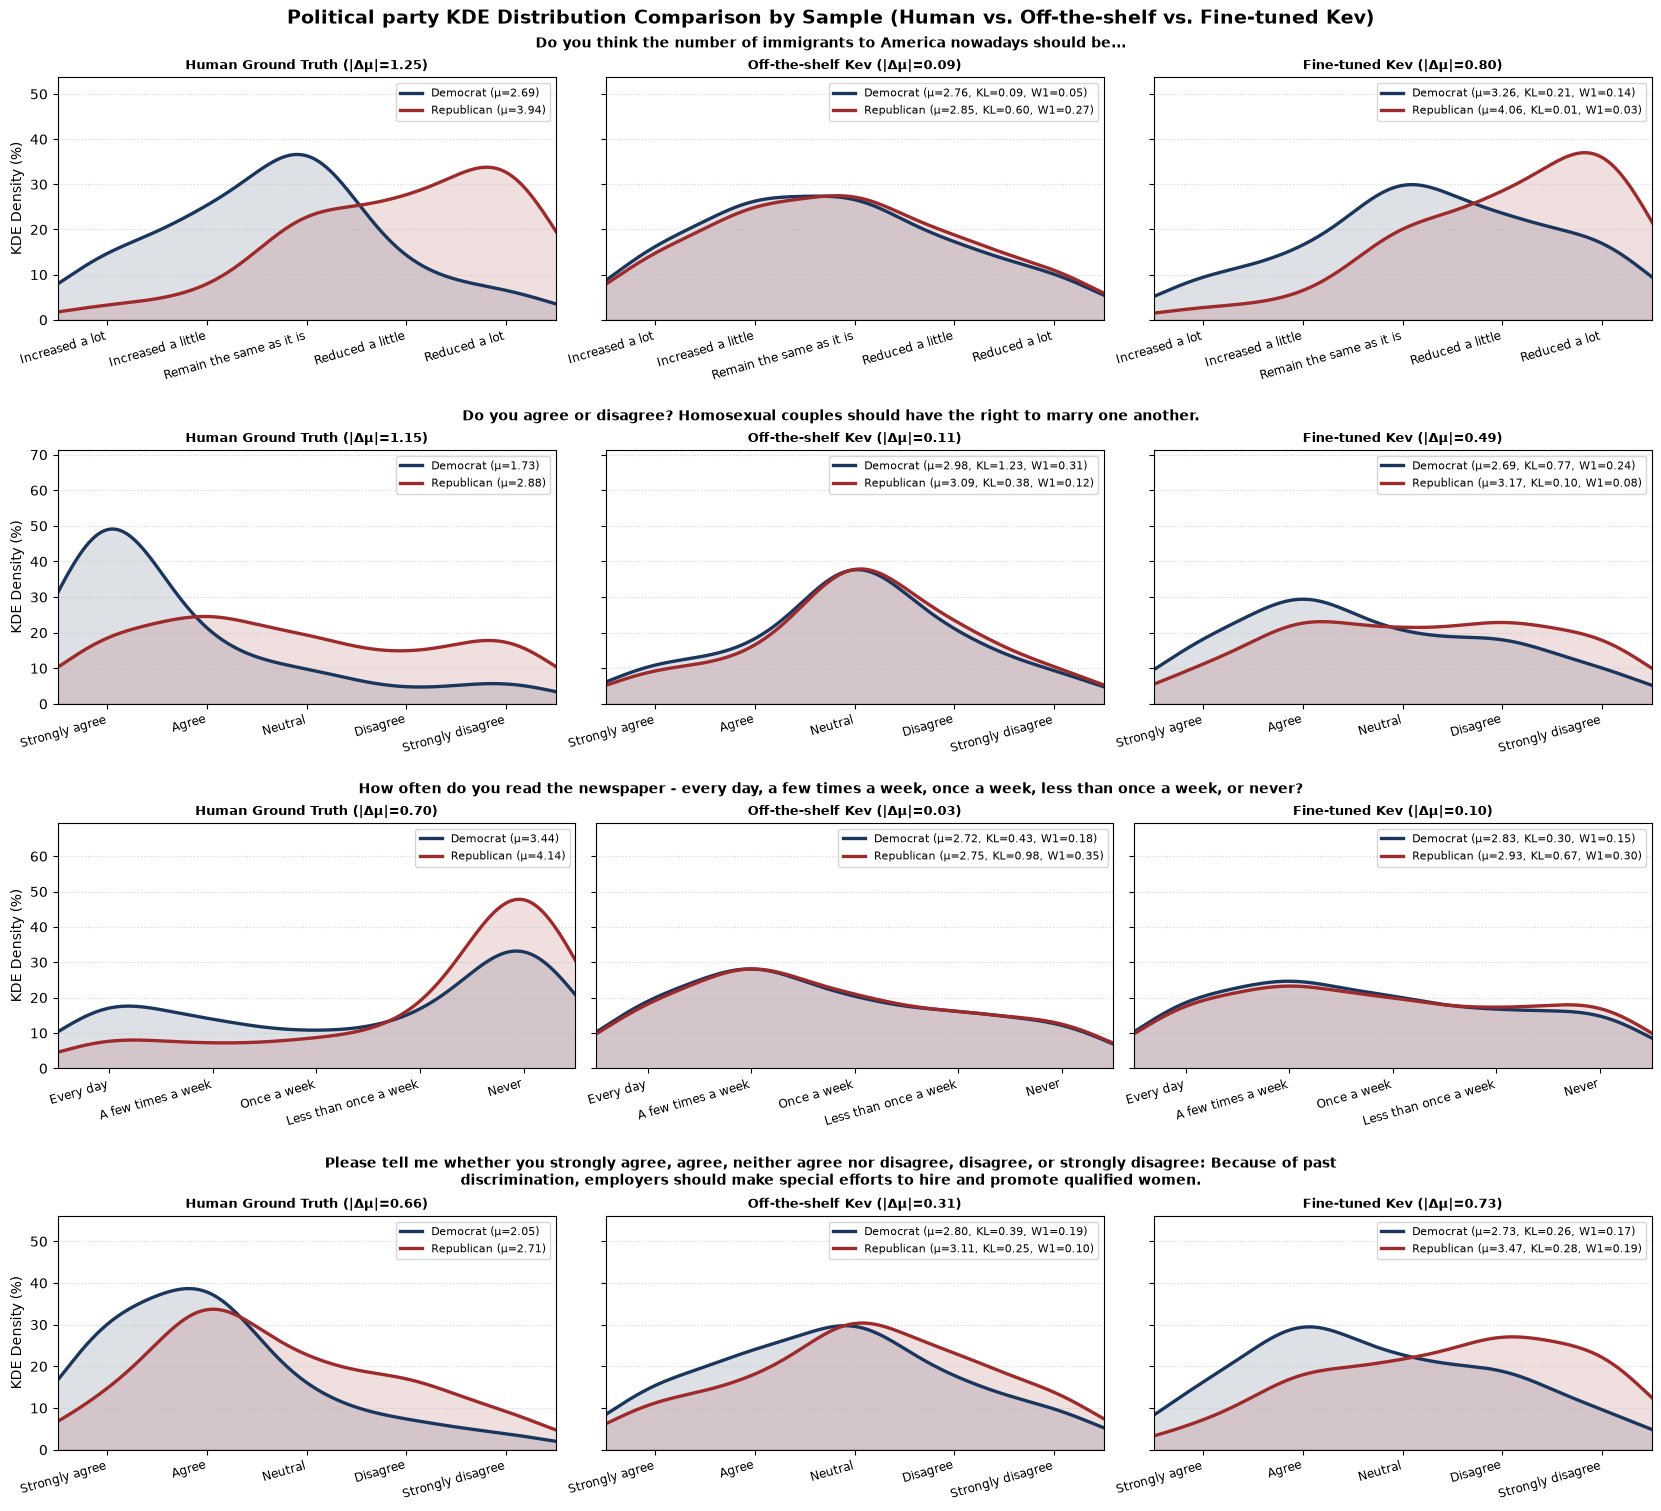

In [60]:
import textwrap

def dist_kl_w1(human_dist, model_dist):
    clipped = np.clip(model_dist, 1e-12, 1.0)
    mask = human_dist > 0
    kl = float(np.sum(human_dist[mask] * np.log2(human_dist[mask] / clipped[mask])))
    w1 = float(np.abs(np.cumsum(human_dist)[:-1] - np.cumsum(model_dist)[:-1]).sum() / (len(human_dist) - 1))
    return kl, w1

def discrete_kde_curve(probs, x_grid, bw=0.55):
    centers = np.arange(len(probs), dtype=float)
    kernels = np.exp(-0.5 * ((x_grid[:, None] - centers[None, :]) / bw) ** 2) / (bw * np.sqrt(2.0 * np.pi))
    return (kernels @ probs) * 100.0

fig = plt.figure(figsize=(16.5, 15.0), constrained_layout=True)
subfigs = fig.subfigures(4, 1, hspace=0.05)

sample_sources = [
    ("Human Ground Truth", lambda qid, lvl: records_by_qid[qid][lvl]["human_dist"]),
    ("Off-the-shelf Kev", lambda qid, lvl: kev_by_qid[qid][lvl]),
    ("Fine-tuned Kev", lambda qid, lvl: ft_by_qid[qid][lvl]),
]

for row_idx, (subfig, (_, row)) in enumerate(zip(subfigs, mixed_df[["qid", "question"]].head(4).iterrows())):
    qid = row["qid"]
    opts = records_by_qid[qid][attr_levels[0]]["option_texts"]
    short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral") for o in opts]
    x = np.arange(len(opts), dtype=float)
    x_grid = np.linspace(-0.6, len(opts) - 0.4, 300)
    scale_pts = np.arange(1, len(opts) + 1, dtype=float)

    wrapped_q = textwrap.fill(f"{row['question']}", width=130)
    subfig.suptitle(wrapped_q, fontsize=10.0, fontweight="bold")
    axes_row = subfig.subplots(1, 3, sharey=True)

    for col_idx, (sample_name, get_dist) in enumerate(sample_sources):
        ax = axes_row[col_idx]
        means = []
        top_y = 0.0

        for i, lvl in enumerate(attr_levels):
            dist = get_dist(qid, lvl)
            kde_vals = discrete_kde_curve(dist, x_grid)
            lvl_mean = float(np.dot(scale_pts, dist))
            means.append(lvl_mean)
            top_y = max(top_y, float(kde_vals.max()))

            if sample_name == "Human Ground Truth":
                lvl_label = f"{lvl} (μ={lvl_mean:.2f})"
            else:
                h_dist = records_by_qid[qid][lvl]["human_dist"]
                lvl_kl, lvl_w1 = dist_kl_w1(h_dist, dist)
                lvl_label = f"{lvl} (μ={lvl_mean:.2f}, KL={lvl_kl:.2f}, W1={lvl_w1:.2f})"

            color = LANCET_PALETTE[i % len(LANCET_PALETTE)]
            ax.fill_between(x_grid, kde_vals, color=color, alpha=0.15)
            ax.plot(x_grid, kde_vals, color=color, linewidth=2.4, linestyle="-", label=lvl_label)

        ax.set_ylim(0, max(ax.get_ylim()[1], top_y * 1.45))
        ax.set_xlim(-0.5, len(opts) - 0.5)
        ax.set_xticks(x)
        ax.set_xticklabels(short_opts, rotation=16, ha="right", fontsize=8.5)
        ax.set_title(
            f"{sample_name} (|Δμ|={max(means) - min(means):.2f})",
            fontsize=9.5,
            fontweight="bold",
        )
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.legend(frameon=True, fontsize=8, loc="upper right")
        if col_idx == 0:
            ax.set_ylabel("KDE Density (%)")

fig.suptitle(f"{attr_label} KDE Distribution Comparison by Sample (Human vs. Off-the-shelf vs. Fine-tuned Kev)", fontsize=13.5, fontweight="bold")

fig_dir = Path("../manuscript/figures")
fig.savefig(fig_dir / "gender_mixed_kde_by_sample_subpop.pdf", bbox_inches="tight")
fig.savefig(fig_dir / "gender_mixed_kde_by_sample_subpop.png", dpi=300, bbox_inches="tight")
plt.show()

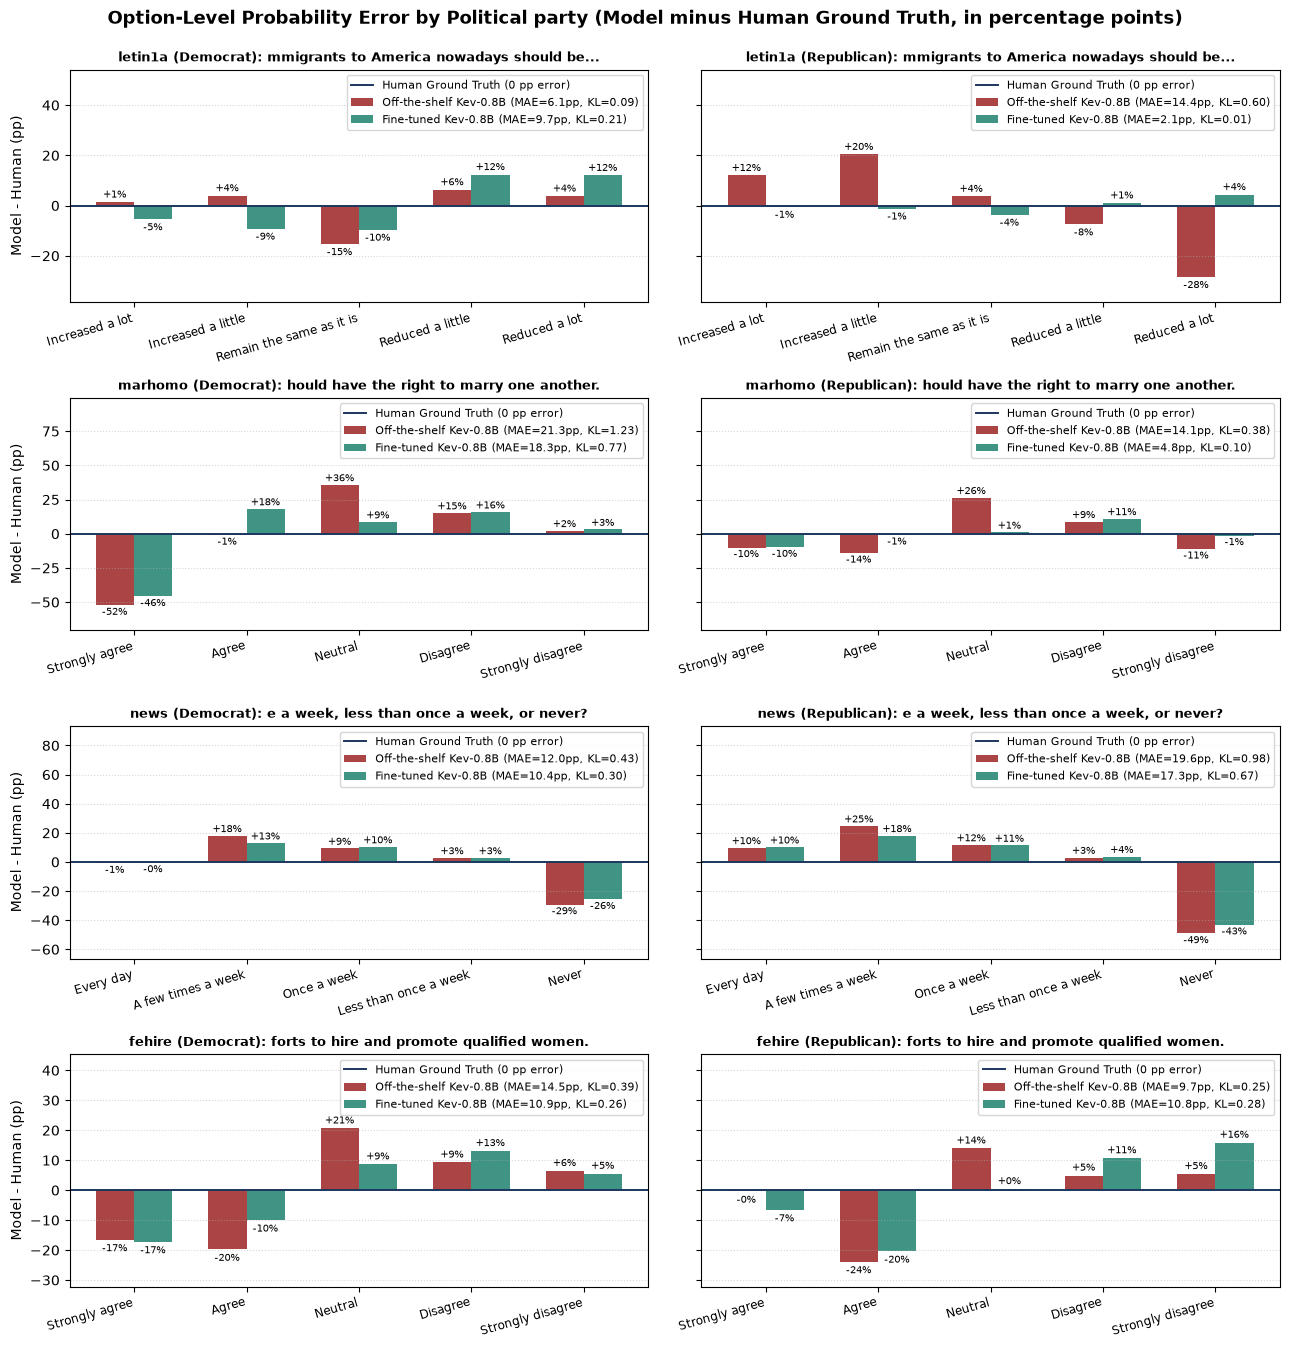

In [58]:
n_lvls = len(attr_levels)
fig, axes = plt.subplots(4, n_lvls, figsize=(6.5 * n_lvls, 13.5), sharey="row", squeeze=False)
bar_w = 0.34

for row_idx, (_, row) in enumerate(mixed_df[["qid", "question"]].head(4).iterrows()):
    qid = row["qid"]
    opts = records_by_qid[qid][attr_levels[0]]["option_texts"]
    short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral") for o in opts]
    x = np.arange(len(opts))

    for col_idx, lvl in enumerate(attr_levels):
        ax = axes[row_idx, col_idx]
        rec = records_by_qid[qid][lvl]
        h_dist = rec["human_dist"]
        k_dist = kev_by_qid[qid][lvl]
        f_dist = ft_by_qid[qid][lvl]

        k_diff = (k_dist - h_dist) * 100.0
        f_diff = (f_dist - h_dist) * 100.0
        k_mae = float(np.abs(k_diff).mean())
        f_mae = float(np.abs(f_diff).mean())
        k_kl, k_w1 = dist_kl_w1(h_dist, k_dist)
        f_kl, f_w1 = dist_kl_w1(h_dist, f_dist)

        ax.axhline(0.0, color="#1B365D", linewidth=1.4, linestyle="-", label="Human Ground Truth (0 pp error)")
        b_k = ax.bar(x - bar_w / 2, k_diff, width=bar_w, color="#9E2A2B", alpha=0.88,
                     label=f"Off-the-shelf Kev-0.8B (MAE={k_mae:.1f}pp, KL={k_kl:.2f})")
        b_f = ax.bar(x + bar_w / 2, f_diff, width=bar_w, color="#2E8B78", alpha=0.92,
                     label=f"Fine-tuned Kev-0.8B (MAE={f_mae:.1f}pp, KL={f_kl:.2f})")

        for bar in list(b_k) + list(b_f):
            h = bar.get_height()
            va = "bottom" if h >= 0 else "top"
            offset = 0.8 if h >= 0 else -1.2
            ax.text(bar.get_x() + bar.get_width() / 2, h + offset, f"{h:+.0f}%", ha="center", va=va, fontsize=7.5)

        max_abs = max(np.abs(k_diff).max(), np.abs(f_diff).max(), 20.0)
        cur_low, cur_high = ax.get_ylim()
        ax.set_ylim(min(cur_low, -max_abs * 1.35), max(cur_high, max_abs * 1.90))
        ax.set_xticks(x)
        ax.set_xticklabels(short_opts, rotation=16, ha="right", fontsize=8.5)
        ax.set_title(f"{qid} ({lvl}): {row['question'][-42:]}", fontsize=9.5, fontweight="bold")
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.legend(frameon=True, fontsize=8, loc="upper right")
        if col_idx == 0:
            ax.set_ylabel("Model - Human (pp)")

fig.suptitle(f"Option-Level Probability Error by {attr_label} (Model minus Human Ground Truth, in percentage points)", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()

fig_dir = Path("../manuscript/figures")
fig.savefig(fig_dir / "gender_mixed_diff_vs_human_subpop.pdf", bbox_inches="tight")
fig.savefig(fig_dir / "gender_mixed_diff_vs_human_subpop.png", dpi=300, bbox_inches="tight")
plt.show()